# 📊 Redes sociales
## ¿El impacto es igual para todos los estudiantes?

**Laboratorio de Métodos Cuantitativos Aplicados a la Gestión**

### Trabajo práctico grupal

**Objetivo general:** analizar el impacto del uso de redes sociales en estudiantes, poniendo el foco en dos preguntas:

- ¿Existen diferencias en el impacto según la **edad** del estudiante?
- ¿Existen diferencias entre estudiantes de **países con distinto nivel de desarrollo**?

Para responder estas preguntas se realizará un análisis exploratorio del dataset, incluyendo limpieza y transformación de variables, estadística descriptiva y visualizaciones.

---

# 01 | Preparación del análisis

En esta primera etapa se importan las librerías necesarias y se carga el dataset utilizado en el trabajo.

El objetivo es verificar que los datos hayan sido importados correctamente y conocer su estructura antes de comenzar con el análisis.

In [ ]:
# Cargo todas las librerias necesarias para procesar los datos.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Cargamos directamente el dataset elegido desde nuestro repositorio.

url = "https://raw.githubusercontent.com/Chaile-Mendez/tp-analisis-labo/Facu/data/raw/dataset_final"

df = pd.read_csv(url)

# 02 | Exploración inicial del dataset

Antes de analizar las preguntas de investigación, se realiza una inspección general del conjunto de datos.

Se busca identificar:

- cantidad de observaciones y variables;
- tipo de cada variable;
- presencia de valores faltantes;
- posibles duplicados;
- distribución inicial de las variables relevantes.

Esta etapa permite detectar problemas de calidad de datos y definir qué transformaciones serán necesarias para el análisis posterior.

In [ ]:
# Muestro las primeras filas de nuestro dataset

df.head()

,Student_ID,Age,Gender,Academic_Level,Country,Avg_Daily_Usage_Hours,Most_Used_Platform,Affects_Academic_Performance,Sleep_Hours_Per_Night,Mental_Health_Score,Relationship_Status
0,788,22,Male,Graduate,Canada,4.6,Instagram,No,6.7,7.0,NaN
1,703,24,Male,Undergraduate,USA,4.7,YouTube,No,7.0,6.2,NaN
2,610,24,Male,Graduate,India,2.7,Instagram,No,8.6,7.8,NaN
3,699,22,Female,Graduate,USA,6.5,YouTube,Yes,5.4,5.0,NaN
4,302,21,Male,High School,Australia,6.8,YouTube,Yes,5.7,5.0,NaN


In [ ]:
# Muestro las ultimas filas de nuestro dataset

df.tail()

,Student_ID,Age,Gender,Academic_Level,Country,Avg_Daily_Usage_Hours,Most_Used_Platform,Affects_Academic_Performance,Sleep_Hours_Per_Night,Mental_Health_Score,Relationship_Status
1738,701,20,Female,Undergraduate,Italy,4.7,TikTok,No,7.2,7.0,In Relationship
1739,702,23,Male,Graduate,Russia,6.8,Instagram,Yes,5.9,4.0,Single
1740,703,21,Female,Undergraduate,China,5.6,WeChat,Yes,6.7,6.0,In Relationship
1741,704,24,Male,Graduate,Japan,4.3,Twitter,No,7.5,8.0,Single
1742,705,19,Female,Undergraduate,Poland,6.2,Facebook,Yes,6.3,5.0,Single


In [ ]:
# Definimos que tipo de datos tienen nuestro dataset

df.dtypes

,0
Student_ID,int64
Age,int64
Gender,object
Academic_Level,object
Country,object
Avg_Daily_Usage_Hours,float64
Most_Used_Platform,object
Affects_Academic_Performance,object
Sleep_Hours_Per_Night,float64
Mental_Health_Score,float64


In [ ]:
# Valores faltantes
df.isna().sum().sort_values(ascending=False)

,0
Relationship_Status,1038
Age,0
Student_ID,0
Gender,0
Academic_Level,0
Avg_Daily_Usage_Hours,0
Country,0
Most_Used_Platform,0
Affects_Academic_Performance,0
Sleep_Hours_Per_Night,0


In [ ]:
# Registros duplicados
print("Duplicados:", df.duplicated().sum())

Duplicados: 0


### Tratamiento de la variable `Relationship_Status`

Durante la exploración inicial se observó una cantidad considerable de valores faltantes en la variable `Relationship_Status`.

Dado que esta variable no resulta indispensable para responder las preguntas principales del análisis —centradas en las diferencias según la edad de los estudiantes y el nivel de desarrollo de sus países— se decidió excluirla del conjunto de variables utilizadas.

Esta decisión permite simplificar el análisis sin eliminar observaciones completas del dataset únicamente por la ausencia de información sobre el estado de relación del estudiante.

In [ ]:
faltantes_relationship = df["Relationship_Status"].isna().sum()
porcentaje_relationship = df["Relationship_Status"].isna().mean() * 100

print("Valores faltantes:", faltantes_relationship)
print(f"Porcentaje de faltantes: {porcentaje_relationship:.2f}%")

Valores faltantes: 1038
Porcentaje de faltantes: 59.55%


In [ ]:
df = df.drop(columns=["Relationship_Status"]) # Elimina únicamente la columna Relationship_Status, pero mantiene todas las filas del dataset.

In [ ]:
df.columns # Verificamos que efectivamente desapareció

Index(['Student_ID', 'Age', 'Gender', 'Academic_Level', 'Country',
       'Avg_Daily_Usage_Hours', 'Most_Used_Platform',
       'Affects_Academic_Performance', 'Sleep_Hours_Per_Night',
       'Mental_Health_Score'],
      dtype='object')

In [ ]:
# Mostramos estadisticas descriptivas de las columnas numericas del dataframe que efectivamente vamos a usar
df.describe()

,Student_ID,Age,Avg_Daily_Usage_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
count,1743.000000,1743.000000,1743.000000,1743.000000,1743.000000
mean,381.694205,20.725760,4.980034,6.781239,6.212909
std,228.749646,1.507523,1.395759,1.155781,1.152245
min,1.000000,18.000000,1.500000,3.800000,4.000000
25%,188.500000,19.000000,4.000000,5.900000,5.000000
50%,376.000000,21.000000,4.800000,6.800000,6.000000
75%,562.000000,22.000000,5.900000,7.600000,7.000000
max,1000.000000,24.000000,8.500000,9.600000,9.000000


# 3 | Pregunta de investigación

### ¿Cuál es la pregunta?

**¿Existen diferencias en el impacto de las redes sociales sobre los estudiantes según su edad y según el nivel de desarrollo del país en el que viven?**

Para abordar esta pregunta se analizarán variables relacionadas con el uso de redes sociales, el bienestar de los estudiantes y su desempeño académico, comparándolas entre distintos grupos etarios y entre países con diferentes niveles de desarrollo.

### ¿Por qué vale la pena responderla?

El uso de redes sociales forma parte de la vida cotidiana de los estudiantes, pero su impacto puede no ser igual para todos. La edad puede estar asociada con diferentes hábitos de uso, niveles de dependencia y efectos sobre el bienestar o el rendimiento académico.

Al mismo tiempo, el contexto socioeconómico del país puede influir en el acceso a la tecnología, los hábitos digitales y las consecuencias asociadas al uso de redes sociales.

Analizar estas diferencias permite identificar si determinados grupos presentan patrones particulares y comprender mejor qué características pueden estar relacionadas con un mayor o menor impacto de las redes sociales.

### ¿Qué respuesta encontramos?

Esta sección será completada al finalizar el análisis, utilizando los resultados estadísticos y gráficos obtenidos en las siguientes etapas del trabajo.

### 3.1 | Agrupación de edades

Para facilitar la comparación entre estudiantes de distintas edades, se creó una nueva variable categórica denominada `Grupo_Edad`.

Las edades originales, comprendidas entre 18 y 24 años, se agruparon en tres rangos: **18-20**, **21-22** y **23-24 años**. Esta transformación permite resumir la información y comparar de manera más clara posibles diferencias entre grupos etarios.

In [ ]:
# Contamos cuantos estudiantes hay de cada edad

df["Age"].value_counts().sort_index()

# Nos permite verificar que no haya una edad con muy pocos casos. Si un grupo queda demasiado chico, la comparación podría ser poco representativa.

,count
Age,
18,67
19,373
20,379
21,372
22,344
23,120
24,88


In [ ]:
# Creamos tres grupos de edad:
# 18-20 años, 21-22 años y 23-24 años

df["Grupo_Edad"] = pd.cut( # pd.cut(): toma una variable numérica continua, en este caso Age, y la transforma en categorías.
    df["Age"],
    bins=[17, 20, 22, 24], # Definimos los limites
    labels=["18-20", "21-22", "23-24"]
)

In [ ]:
# Revisamos cuántos estudiantes quedaron en cada grupo
df["Grupo_Edad"].value_counts().sort_index()

,count
Grupo_Edad,
18-20,819
21-22,716
23-24,208


La agrupación por edades muestra una distribución desigual entre los tres grupos definidos. La mayor cantidad de observaciones corresponde a estudiantes de **18 a 20 años (819 casos)**, seguida por el grupo de **21 a 22 años (716 casos)**. En cambio, el grupo de **23 a 24 años** cuenta con una cantidad considerablemente menor de observaciones (**208 casos**).

Esta diferencia en el tamaño de los grupos debe tenerse en cuenta al interpretar los resultados, ya que los estadísticos del grupo de mayor edad pueden ser menos estables debido a su menor cantidad de observaciones.

### 3.2 | Clasificación de países según nivel de desarrollo

Para analizar si el impacto de las redes sociales presenta diferencias entre países, se creará una nueva variable denominada `Nivel_Desarrollo`.

Esta variable permitirá agrupar los países del dataset en categorías según su nivel de desarrollo, facilitando posteriormente la comparación de indicadores relacionados con el uso de redes sociales, bienestar y desempeño académico.

In [ ]:
# Mostramos todos los países del dataset sin que Pandas oculte filas
paises = df["Country"].value_counts()

print(paises.to_string())

Country
India              192
USA                155
Canada             112
UK                  88
Australia           80
Germany             60
Spain               54
Mexico              54
France              54
Switzerland         54
Turkey              54
Ireland             54
Denmark             54
Japan               42
Russia              42
Italy               42
Bangladesh          40
Nepal               38
Pakistan            38
Maldives            38
Sri Lanka           38
China               32
Poland              32
South Korea         26
UAE                 16
Singapore           16
New Zealand         16
Brazil              16
Malaysia            16
Netherlands         16
Finland             16
Austria              2
Thailand             2
Philippines          2
Taiwan               2
Indonesia            2
Hong Kong            2
Israel               2
Egypt                2
Morocco              2
Vietnam              2
Belgium              2
Greece               2
Por

In [ ]:
# Obtenemos una lista con los países únicos del dataset
paises_unicos = sorted(df["Country"].dropna().unique())

print(paises_unicos)
print("Cantidad de países:", len(paises_unicos))

['Afghanistan', 'Albania', 'Andorra', 'Argentina', 'Armenia', 'Australia', 'Austria', 'Azerbaijan', 'Bahamas', 'Bahrain', 'Bangladesh', 'Belarus', 'Belgium', 'Bhutan', 'Bolivia', 'Bosnia', 'Brazil', 'Bulgaria', 'Canada', 'Chile', 'China', 'Colombia', 'Costa Rica', 'Croatia', 'Cyprus', 'Czech Republic', 'Denmark', 'Ecuador', 'Egypt', 'Estonia', 'Finland', 'France', 'Georgia', 'Germany', 'Ghana', 'Greece', 'Hong Kong', 'Hungary', 'Iceland', 'India', 'Indonesia', 'Iraq', 'Ireland', 'Israel', 'Italy', 'Jamaica', 'Japan', 'Jordan', 'Kazakhstan', 'Kenya', 'Kosovo', 'Kuwait', 'Kyrgyzstan', 'Latvia', 'Lebanon', 'Liechtenstein', 'Lithuania', 'Luxembourg', 'Malaysia', 'Maldives', 'Malta', 'Mexico', 'Moldova', 'Monaco', 'Montenegro', 'Morocco', 'Nepal', 'Netherlands', 'New Zealand', 'Nigeria', 'North Macedonia', 'Norway', 'Oman', 'Pakistan', 'Panama', 'Paraguay', 'Peru', 'Philippines', 'Poland', 'Portugal', 'Qatar', 'Romania', 'Russia', 'San Marino', 'Serbia', 'Singapore', 'Slovakia', 'Slovenia',

In [ ]:
# Clasificamos los países según el nivel de ingreso del Banco Mundial.
# "Desarrollado" = economías de ingreso alto
# "En desarrollo" = economías de ingreso bajo, medio-bajo o medio-alto

clasificacion_paises = {

    # Desarrollados
    "Andorra": "Desarrollado",
    "Australia": "Desarrollado",
    "Austria": "Desarrollado",
    "Bahamas": "Desarrollado",
    "Bahrain": "Desarrollado",
    "Belgium": "Desarrollado",
    "Bulgaria": "Desarrollado",
    "Canada": "Desarrollado",
    "Chile": "Desarrollado",
    "Costa Rica": "Desarrollado",
    "Croatia": "Desarrollado",
    "Cyprus": "Desarrollado",
    "Czech Republic": "Desarrollado",
    "Denmark": "Desarrollado",
    "Estonia": "Desarrollado",
    "Finland": "Desarrollado",
    "France": "Desarrollado",
    "Germany": "Desarrollado",
    "Greece": "Desarrollado",
    "Hong Kong": "Desarrollado",
    "Hungary": "Desarrollado",
    "Iceland": "Desarrollado",
    "Ireland": "Desarrollado",
    "Israel": "Desarrollado",
    "Italy": "Desarrollado",
    "Japan": "Desarrollado",
    "Kuwait": "Desarrollado",
    "Latvia": "Desarrollado",
    "Liechtenstein": "Desarrollado",
    "Lithuania": "Desarrollado",
    "Luxembourg": "Desarrollado",
    "Malta": "Desarrollado",
    "Monaco": "Desarrollado",
    "Netherlands": "Desarrollado",
    "New Zealand": "Desarrollado",
    "Norway": "Desarrollado",
    "Oman": "Desarrollado",
    "Panama": "Desarrollado",
    "Poland": "Desarrollado",
    "Portugal": "Desarrollado",
    "Qatar": "Desarrollado",
    "Romania": "Desarrollado",
    "Russia": "Desarrollado",
    "San Marino": "Desarrollado",
    "Singapore": "Desarrollado",
    "Slovakia": "Desarrollado",
    "Slovenia": "Desarrollado",
    "South Korea": "Desarrollado",
    "Spain": "Desarrollado",
    "Sweden": "Desarrollado",
    "Switzerland": "Desarrollado",
    "Taiwan": "Desarrollado",
    "Trinidad": "Desarrollado",
    "UAE": "Desarrollado",
    "UK": "Desarrollado",
    "USA": "Desarrollado",
    "Uruguay": "Desarrollado",

    # En desarrollo
    "Afghanistan": "En desarrollo",
    "Albania": "En desarrollo",
    "Argentina": "En desarrollo",
    "Armenia": "En desarrollo",
    "Azerbaijan": "En desarrollo",
    "Bangladesh": "En desarrollo",
    "Belarus": "En desarrollo",
    "Bhutan": "En desarrollo",
    "Bolivia": "En desarrollo",
    "Bosnia": "En desarrollo",
    "Brazil": "En desarrollo",
    "China": "En desarrollo",
    "Colombia": "En desarrollo",
    "Ecuador": "En desarrollo",
    "Egypt": "En desarrollo",
    "Georgia": "En desarrollo",
    "Ghana": "En desarrollo",
    "India": "En desarrollo",
    "Indonesia": "En desarrollo",
    "Iraq": "En desarrollo",
    "Jamaica": "En desarrollo",
    "Jordan": "En desarrollo",
    "Kazakhstan": "En desarrollo",
    "Kenya": "En desarrollo",
    "Kosovo": "En desarrollo",
    "Kyrgyzstan": "En desarrollo",
    "Lebanon": "En desarrollo",
    "Malaysia": "En desarrollo",
    "Maldives": "En desarrollo",
    "Mexico": "En desarrollo",
    "Moldova": "En desarrollo",
    "Montenegro": "En desarrollo",
    "Morocco": "En desarrollo",
    "Nepal": "En desarrollo",
    "Nigeria": "En desarrollo",
    "North Macedonia": "En desarrollo",
    "Pakistan": "En desarrollo",
    "Paraguay": "En desarrollo",
    "Peru": "En desarrollo",
    "Philippines": "En desarrollo",
    "Serbia": "En desarrollo",
    "South Africa": "En desarrollo",
    "Sri Lanka": "En desarrollo",
    "Syria": "En desarrollo",
    "Tajikistan": "En desarrollo",
    "Thailand": "En desarrollo",
    "Turkey": "En desarrollo",
    "Ukraine": "En desarrollo",
    "Uzbekistan": "En desarrollo",
    "Venezuela": "En desarrollo",
    "Vietnam": "En desarrollo",
    "Yemen": "En desarrollo"
}

In [ ]:
# Creamos la nueva variable Nivel_Desarrollo utilizando la clasificación definida anteriormente.

df["Nivel_Desarrollo"] = df["Country"].map(clasificacion_paises)

In [ ]:
# Revisamos si algún país no pudo ser clasificado.

df[df["Nivel_Desarrollo"].isna()]["Country"].unique()

array(['Vatican City'], dtype=object)

Acá hay un caso especial: Vatican City. El Banco Mundial no lo incluye normalmente dentro de esta clasificación por ingreso, por lo que yo no lo asignaría arbitrariamente a uno de los dos grupos. Lo dejaría como faltante en Nivel_Desarrollo y lo excluiría únicamente de las comparaciones que utilicen esta variable.

In [ ]:
# Observamos cuántos estudiantes quedaron en cada grupo.

df["Nivel_Desarrollo"].value_counts(dropna=False)

,count
Nivel_Desarrollo,
Desarrollado,1103
En desarrollo,638
NaN,2


La clasificación por nivel de desarrollo permitió agrupar a la mayoría de los estudiantes en dos categorías: **1.103 estudiantes de países desarrollados** y **638 estudiantes de países en desarrollo**.

La distribución no es completamente equilibrada, ya que el grupo de países desarrollados tiene una mayor cantidad de observaciones. Esta diferencia deberá tenerse en cuenta al interpretar los resultados, especialmente en comparaciones gráficas o estadísticas entre ambos grupos.

Además, quedaron **2 observaciones sin clasificar**, correspondientes a países que no pudieron ser asignados mediante el criterio utilizado.

### 3.3 | Comparación de indicadores mediante agrupaciones

Una vez realizadas las transformaciones necesarias, se agrupan los estudiantes según las nuevas variables `Grupo_Edad` y `Nivel_Desarrollo`.

A partir de estas agrupaciones se calcularán estadísticos de resumen, como la **media** y la **mediana**, sobre distintas variables relacionadas con el impacto de las redes sociales.

Este análisis permitirá observar si existen diferencias entre los grupos etarios y entre estudiantes de países con distinto nivel de desarrollo.

In [ ]:
# Resumimos los principales indicadores según el grupo de edad.
# Esto nos permite comparar en una misma tabla el uso de redes,
# las horas de sueño y el puntaje de salud mental.

resumen_edad = df.groupby("Grupo_Edad")[
    ["Avg_Daily_Usage_Hours",
     "Sleep_Hours_Per_Night",
     "Mental_Health_Score"]
].agg(["mean", "median"]).round(2)

resumen_edad

/tmp/ipykernel_8850/355211931.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  resumen_edad = df.groupby("Grupo_Edad")[


Avg_Daily_Usage_Hours        Sleep_Hours_Per_Night         \
                            mean median                  mean median   
Grupo_Edad                                                             
18-20                       5.09    4.9                  6.68    6.6   
21-22                       4.91    4.7                  6.90    6.9   
23-24                       4.81    4.8                  6.75    7.0   

           Mental_Health_Score         
                          mean median  
Grupo_Edad                             
18-20                     6.10    6.0  
21-22                     6.28    6.0  
23-24                     6.44    6.5

In [ ]:
# Resumimos los principales indicadores según
# el nivel de desarrollo del país.

resumen_desarrollo = df.groupby("Nivel_Desarrollo")[
    ["Avg_Daily_Usage_Hours",
     "Sleep_Hours_Per_Night",
     "Mental_Health_Score"]
].agg(["mean", "median"]).round(2)

resumen_desarrollo

Avg_Daily_Usage_Hours        Sleep_Hours_Per_Night         \
                                  mean median                  mean median   
Nivel_Desarrollo                                                             
Desarrollado                      4.83    4.6                  6.97    7.1   
En desarrollo                     5.25    5.2                  6.45    6.3   

                 Mental_Health_Score         
                                mean median  
Nivel_Desarrollo                             
Desarrollado                    6.37    6.3  
En desarrollo                   5.94    6.0

In [ ]:
# Calculamos la proporción de respuestas dentro de cada grupo de edad.

pd.crosstab(
    df["Grupo_Edad"],
    df["Affects_Academic_Performance"],
    normalize="index"
) * 100

Affects_Academic_Performance,No,Yes
Grupo_Edad,,
18-20,33.089133,66.910867
21-22,36.731844,63.268156
23-24,52.403846,47.596154


In [ ]:
# Comparamos el impacto académico percibido
# según el nivel de desarrollo del país.

pd.crosstab(
    df["Nivel_Desarrollo"],
    df["Affects_Academic_Performance"],
    normalize="index"
) * 100

Affects_Academic_Performance,No,Yes
Nivel_Desarrollo,,
Desarrollado,43.517679,56.482321
En desarrollo,25.548589,74.451411


### Criterio de interpretación

Para este análisis se considera que un valor más alto de `Mental_Health_Score` representa un mejor estado de salud mental.

Por lo tanto, al comparar grupos, un puntaje promedio más bajo será interpretado como un indicador menos favorable de bienestar mental.

### Interpretación de los resultados

Los resultados descriptivos sugieren que el grupo de **18 a 20 años** presenta, en términos generales, los indicadores más desfavorables entre los grupos etarios analizados. Esta conclusión se basa en la comparación conjunta de variables relacionadas con el tiempo de uso de redes sociales, las horas de sueño, la salud mental y el impacto académico percibido.

De manera similar, los estudiantes pertenecientes a **países en desarrollo** muestran resultados menos favorables en varios de estos indicadores en comparación con aquellos de países desarrollados.

Estos resultados describen diferencias observadas dentro de la muestra y no permiten establecer relaciones causales.

# 4 | Visualización de resultados

Para complementar el análisis descriptivo, se utilizan gráficos que permiten comparar visualmente los principales indicadores según el grupo de edad y el nivel de desarrollo del país.

Las visualizaciones se centran en las variables vinculadas con el uso de redes sociales, las horas de sueño, la salud mental y el impacto académico percibido.

### 4.1 | Uso diario de redes sociales según grupo de edad

En este gráfico se compara el **promedio de horas diarias de uso de redes sociales** entre los distintos grupos etarios.

El objetivo es identificar si existen diferencias en la intensidad de uso según la edad de los estudiantes y observar qué grupo presenta una mayor exposición diaria a las redes sociales.

---

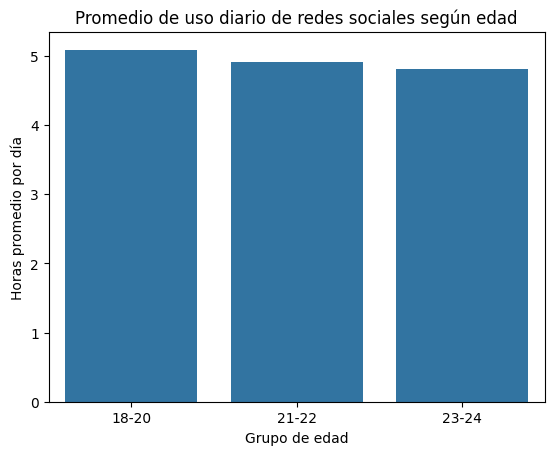

In [ ]:
# Calculamos el promedio de horas diarias de uso
# para cada grupo de edad.

uso_edad = (
    df.groupby("Grupo_Edad", observed=True)["Avg_Daily_Usage_Hours"]
      .mean()
      .reset_index()
)

# Creamos el gráfico
sns.barplot(
    data=uso_edad,
    x="Grupo_Edad",
    y="Avg_Daily_Usage_Hours"
)

plt.title("Promedio de uso diario de redes sociales según edad")
plt.xlabel("Grupo de edad")
plt.ylabel("Horas promedio por día")
plt.show()

### 4.2 | Salud mental según grupo de edad

A continuación se compara el **puntaje promedio de salud mental** entre los grupos de edad definidos.

Considerando que un valor más alto de `Mental_Health_Score` representa una mejor salud mental, el gráfico permite identificar qué grupos presentan resultados relativamente más favorables o desfavorables en este indicador.

---

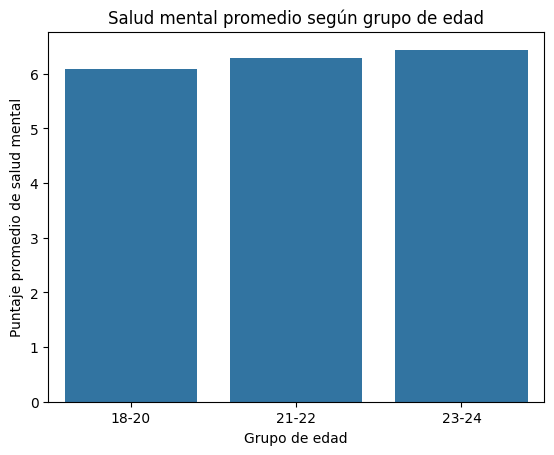

In [ ]:
# Calculamos el puntaje promedio de salud mental
# para cada grupo de edad.

salud_edad = (
    df.groupby("Grupo_Edad", observed=True)["Mental_Health_Score"]
      .mean()
      .reset_index()
)

sns.barplot(
    data=salud_edad,
    x="Grupo_Edad",
    y="Mental_Health_Score"
)

plt.title("Salud mental promedio según grupo de edad")
plt.xlabel("Grupo de edad")
plt.ylabel("Puntaje promedio de salud mental")
plt.show()

### 4.3 | Uso diario de redes sociales según nivel de desarrollo

Este gráfico compara el **promedio de horas diarias de uso de redes sociales** entre estudiantes de países desarrollados y países en desarrollo.

La visualización permite analizar si el nivel de desarrollo del país está asociado con diferencias en la intensidad de uso de las redes sociales.

---

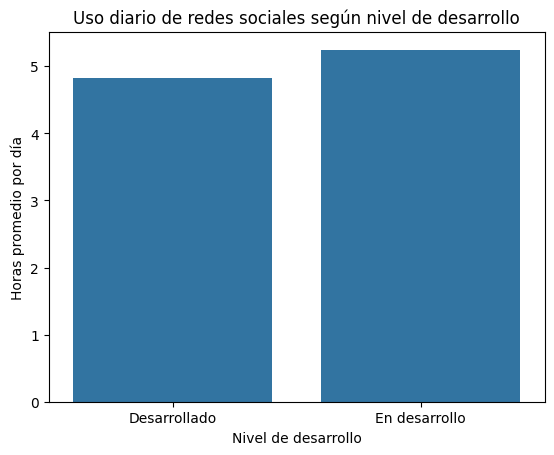

In [ ]:
# Calculamos el promedio de uso diario según
# el nivel de desarrollo del país.

uso_desarrollo = (
    df.groupby("Nivel_Desarrollo")["Avg_Daily_Usage_Hours"]
      .mean()
      .reset_index()
)

sns.barplot(
    data=uso_desarrollo,
    x="Nivel_Desarrollo",
    y="Avg_Daily_Usage_Hours"
)

plt.title("Uso diario de redes sociales según nivel de desarrollo")
plt.xlabel("Nivel de desarrollo")
plt.ylabel("Horas promedio por día")
plt.show()

### 4.4 | Salud mental según nivel de desarrollo

En este gráfico se compara el **puntaje promedio de salud mental** entre estudiantes de países desarrollados y en desarrollo.

Dado que los valores más altos indican una mejor salud mental, la comparación permite observar si alguno de los grupos presenta indicadores de bienestar mental relativamente menos favorables.

---

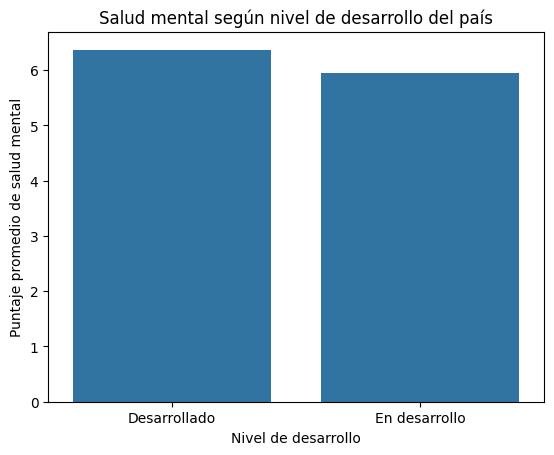

In [ ]:
# Comparamos el puntaje promedio de salud mental
# entre países desarrollados y en desarrollo.

salud_desarrollo = (
    df.groupby("Nivel_Desarrollo")["Mental_Health_Score"]
      .mean()
      .reset_index()
)

sns.barplot(
    data=salud_desarrollo,
    x="Nivel_Desarrollo",
    y="Mental_Health_Score"
)

plt.title("Salud mental según nivel de desarrollo del país")
plt.xlabel("Nivel de desarrollo")
plt.ylabel("Puntaje promedio de salud mental")
plt.show()

### 4.5 | Impacto académico percibido según grupo de edad

Para analizar el impacto sobre el rendimiento académico, se comparan las **proporciones de estudiantes que indican si las redes sociales afectan o no su desempeño académico**.

Se utiliza un gráfico de barras apiladas debido a que `Affects_Academic_Performance` es una variable categórica. De esta manera, es posible comparar el porcentaje de respuestas dentro de cada grupo de edad, independientemente de las diferencias en el tamaño de los grupos.

---

In [ ]:
# Calculamos qué porcentaje de cada grupo de edad
# responde cada categoría de impacto académico.

impacto_edad = pd.crosstab(
    df["Grupo_Edad"],
    df["Affects_Academic_Performance"],
    normalize="index"
) * 100

impacto_edad

Affects_Academic_Performance,No,Yes
Grupo_Edad,,
18-20,33.089133,66.910867
21-22,36.731844,63.268156
23-24,52.403846,47.596154


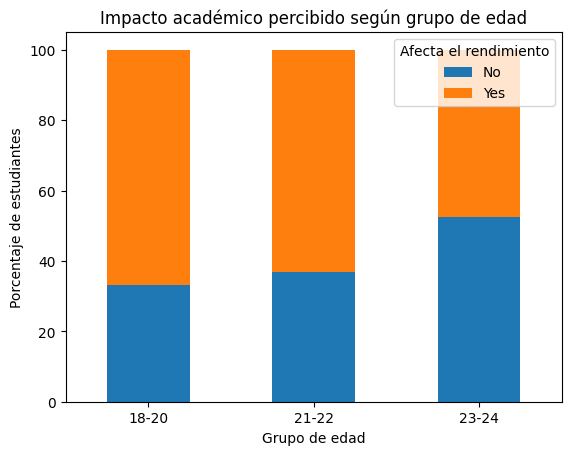

In [ ]:
# Creamos un gráfico de barras apiladas
# para visualizar la proporción de respuestas.

impacto_edad.plot(
    kind="bar",
    stacked=True
)

plt.title("Impacto académico percibido según grupo de edad")
plt.xlabel("Grupo de edad")
plt.ylabel("Porcentaje de estudiantes")
plt.legend(title="Afecta el rendimiento")
plt.xticks(rotation=0)
plt.show()

### 4.6 | Distribución del uso diario según grupo de edad

Finalmente, se utiliza un diagrama de caja (*boxplot*) para analizar la distribución de las horas diarias de uso de redes sociales en cada grupo etario.

A diferencia del gráfico de promedios, esta visualización permite observar no solo la tendencia central, sino también la **dispersión de los datos y la presencia de posibles valores extremos**, proporcionando una visión más completa de las diferencias entre los grupos.

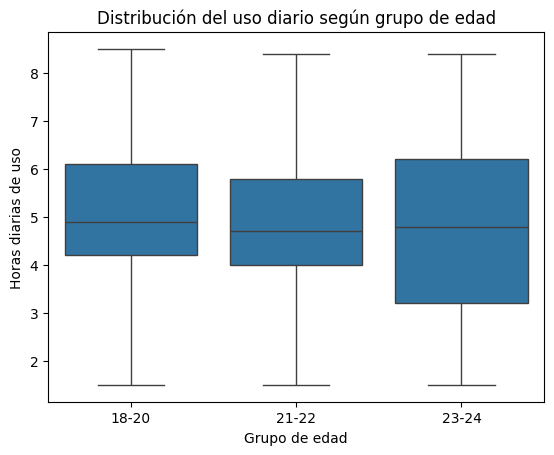

In [ ]:
# Mostramos la distribución completa de las horas de uso
# dentro de cada grupo de edad.

sns.boxplot(
    data=df,
    x="Grupo_Edad",
    y="Avg_Daily_Usage_Hours"
)

plt.title("Distribución del uso diario según grupo de edad")
plt.xlabel("Grupo de edad")
plt.ylabel("Horas diarias de uso")
plt.show()